# COMP 472 · Clustering Experiment (k-Means)

**Fall 2026 · Kaggle Project**

This notebook runs k-Means clustering on the **sentiment** dataset. k-Means does not use the labels. We use the labels only after clustering, to measure how well the clusters match the three sentiment classes.

This experiment answers three of the suggested questions:

1. Do the sentiment examples naturally separate into negative, neutral and positive groups?
2. How closely do the clusters correspond to the true labels?
3. How does changing the number of clusters affect the results?

**Sections:** 1 Setup · 2 Data · 3 k-Means · 4 Evaluation measures · 5 Three clusters · 6 Changing the number of clusters · 7 Conclusions

## 1 · Setup

We fix the random seed so that the results can be reproduced, and print the library versions.

In [ ]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

SEED = 42
np.random.seed(SEED)

print("Python      ", platform.python_version())
print("NumPy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.12.3
NumPy        2.5.5
pandas       3.1.1
scikit-learn 1.9.1


## 2 · Data

We use all 12,000 labelled sentiment examples. No train/validation split is needed, because k-Means never sees the labels.

We standardize each feature to a mean of 0 and a standard deviation of 1, as in Lab 6. k-Means uses Euclidean distance. Without standardization, features with a larger range would have more influence on the distance.

In [ ]:
sentiment = pd.read_csv("sentiment_train.csv")
X = sentiment.drop(columns=["id", "label"]).to_numpy(np.float64)
y = sentiment["label"].to_numpy()
SENT_NAMES = ["Negative", "Neutral", "Positive"]

std = X.std(axis=0)
std[std < 1e-8] = 1.0
X = (X - X.mean(axis=0)) / std

print("examples:", X.shape[0], " features:", X.shape[1])
print("examples per class:", dict(zip(SENT_NAMES, np.bincount(y))))

examples: 12000  features: 768
examples per class: {'Negative': np.int64(4000), 'Neutral': np.int64(4000), 'Positive': np.int64(4000)}


## 3 · k-Means

The algorithm follows Lab 6:

1. Choose the number of clusters k.
2. Pick k random examples as the starting centroids.
3. **Assign** each example to the nearest centroid (Euclidean distance).
4. **Update** each centroid to the mean of the examples assigned to it.
5. Repeat steps 3 and 4 until the centroids stop moving, or until a maximum number of iterations.

**Inertia** is the sum of the squared distances from each example to its centroid. k-Means tries to make it as small as possible.

The result depends on the starting centroids. We therefore run k-Means 5 times with different starting centroids and keep the run with the lowest inertia.

The code uses NumPy matrix operations instead of Python loops, so it runs quickly on 12,000 × 768 values.

In [ ]:
def initialize_centroids(X, k, rng):
    return X[rng.choice(len(X), size=k, replace=False)].copy()

def squared_distances(X, centroids):
    # ||x - c||^2 = ||x||^2 + ||c||^2 - 2 x.c, for every example x and every centroid c
    return (X ** 2).sum(axis=1)[:, None] + (centroids ** 2).sum(axis=1)[None, :] - 2 * X @ centroids.T

def assign_clusters(X, centroids):
    return squared_distances(X, centroids).argmin(axis=1)

def update_centroids(X, labels, k, rng):
    centroids = np.empty((k, X.shape[1]))
    for j in range(k):
        members = X[labels == j]
        if len(members) > 0:
            centroids[j] = members.mean(axis=0)
        else:
            centroids[j] = X[rng.integers(len(X))]     # empty cluster: restart it at a random example
    return centroids

def compute_inertia(X, labels, centroids):
    return float(((X - centroids[labels]) ** 2).sum())

class KMeans:
    def __init__(self, k, n_init=5, max_iter=300, tol=1e-6, seed=SEED):
        self.k, self.n_init, self.max_iter, self.tol, self.seed = k, n_init, max_iter, tol, seed

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        best = None
        for run in range(self.n_init):
            centroids = initialize_centroids(X, self.k, rng)
            for iteration in range(1, self.max_iter + 1):
                labels = assign_clusters(X, centroids)
                new_centroids = update_centroids(X, labels, self.k, rng)
                shift = np.linalg.norm(new_centroids - centroids, axis=1).max()   # largest centroid move
                centroids = new_centroids
                if shift < self.tol:
                    break
            labels = assign_clusters(X, centroids)
            inertia = compute_inertia(X, labels, centroids)
            if best is None or inertia < best[0]:
                best = (inertia, labels, centroids, iteration)
        self.inertia_, self.labels_, self.centroids_, self.n_iter_ = best
        return self

## 4 · Evaluation measures

These measures compare the clusters with the true labels (external evaluation, Lab 6):

* **Purity:** give each cluster the label that is most common in it, then count the fraction of examples that have that label. With three classes of equal size, a random split into 3 clusters gives a purity of about 0.33. A perfect match gives 1.
* **Adjusted Rand Index (ARI):** measures how often pairs of examples are treated the same way by the clusters and by the labels (same group or different groups). It is adjusted so that random clusters give about 0 and a perfect match gives 1.
* **Normalized Mutual Information (NMI):** measures how much knowing the cluster of an example tells us about its label. 0 means nothing, 1 means everything.

Purity is written from scratch as in Lab 6. ARI and NMI come from `sklearn.metrics`, which the project allows for metrics.

In [ ]:
def purity(cluster_labels, true_labels):
    total = 0
    for cluster in np.unique(cluster_labels):
        total += np.bincount(true_labels[cluster_labels == cluster]).max()   # size of the most common label
    return total / len(true_labels)

def evaluate(cluster_labels, true_labels):
    return {"purity": purity(cluster_labels, true_labels),
            "ARI": adjusted_rand_score(true_labels, cluster_labels),
            "NMI": normalized_mutual_info_score(true_labels, cluster_labels)}

## 5 · Three clusters

There are three sentiment classes, so we first use k = 3. If the examples naturally separated by sentiment, each cluster would contain mostly one sentiment.

converged after 36 iterations, inertia 8,674,732


,Negative,Neutral,Positive,size
cluster,,,,
0,391,760,467,1618
1,1341,1626,2049,5016
2,2268,1614,1484,5366


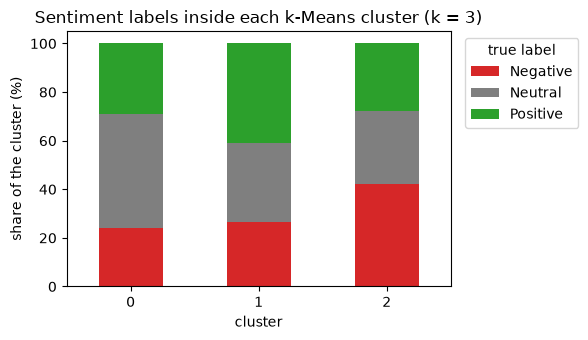

In [ ]:
km3 = KMeans(k=3).fit(X)
print(f"converged after {km3.n_iter_} iterations, inertia {km3.inertia_:,.0f}")

table = pd.crosstab(km3.labels_, y, rownames=["cluster"], colnames=["true label"])
table.columns = SENT_NAMES
table["size"] = table.sum(axis=1)
display(table)

shares = table[SENT_NAMES].div(table["size"], axis=0) * 100
shares.plot(kind="bar", stacked=True, figsize=(6, 3.5), color=["#d62728", "#7f7f7f", "#2ca02c"])
plt.ylabel("share of the cluster (%)"); plt.xlabel("cluster"); plt.xticks(rotation=0)
plt.title("Sentiment labels inside each k-Means cluster (k = 3)")
plt.legend(title="true label", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

To judge these numbers, we also compute the measures for **random clusters of the same sizes**. We get them by shuffling the cluster labels.

In [ ]:
rng = np.random.default_rng(SEED)
random_clusters = rng.permutation(km3.labels_)

display(pd.DataFrame({"k-Means (k = 3)": evaluate(km3.labels_, y),
                      "random clusters, same sizes": evaluate(random_clusters, y)}).T.round(3))

,purity,ARI,NMI
k-Means (k = 3),0.423,0.02,0.019
"random clusters, same sizes",0.339,-0.00,0.000


**Observation.** The three clusters have 1,618, 5,016 and 5,366 examples. Every cluster contains many examples of all three sentiments. The most common label covers only 47.0% of cluster 0 (neutral), 40.8% of cluster 1 (positive) and 42.3% of cluster 2 (negative).

Purity is 0.423, compared with 0.339 for random clusters of the same sizes. ARI (0.020) and NMI (0.019) are close to 0. The clusters match the sentiment labels only a little better than random clusters. **The examples do not naturally separate into negative, neutral and positive groups.**

## 6 · Changing the number of clusters

We run k-Means for k = 1 to 10 and record the inertia and the three measures.

* The **elbow method** (Lab 6) looks for the k where inertia stops dropping quickly.
* Purity tends to increase with k even for random clusters, because smaller clusters are more likely to be dominated by one label. ARI and NMI are less affected by this.

,inertia,purity,ARI,NMI
k,,,,
1,9216000.0,0.333,0.000,0.000
2,8880834.0,0.391,0.014,0.012
3,8674732.0,0.423,0.020,0.019
4,8522804.0,0.431,0.025,0.024
5,8386097.0,0.421,0.022,0.028
6,8290194.0,0.419,0.021,0.026
7,8198161.0,0.450,0.029,0.036
8,8113027.0,0.429,0.022,0.028
9,8038358.0,0.443,0.024,0.032


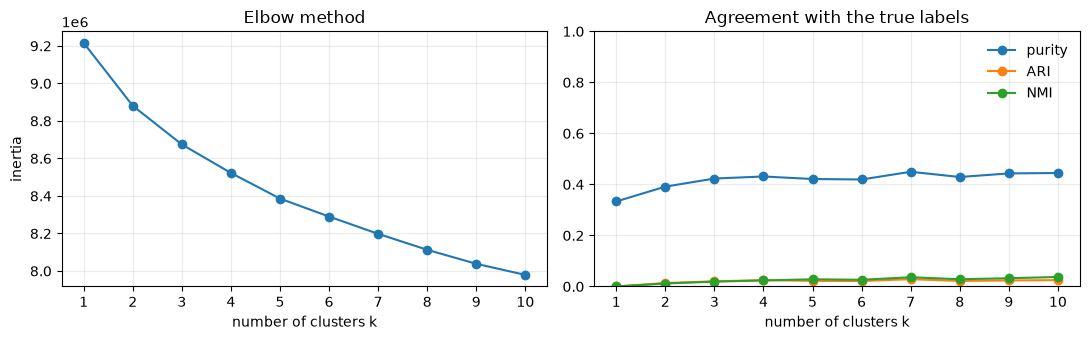

In [ ]:
rows = []
for k in range(1, 11):
    km = KMeans(k=k).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, **evaluate(km.labels_, y)})
sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round({"inertia": 0, "purity": 3, "ARI": 3, "NMI": 3}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(sweep.index, sweep["inertia"], marker="o")
axes[0].set_title("Elbow method"); axes[0].set_xlabel("number of clusters k"); axes[0].set_ylabel("inertia")
for name in ["purity", "ARI", "NMI"]:
    axes[1].plot(sweep.index, sweep[name], marker="o", label=name)
axes[1].set_title("Agreement with the true labels"); axes[1].set_xlabel("number of clusters k")
axes[1].set_ylim(0, 1); axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xticks(range(1, 11)); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**Observation.** Inertia decreases steadily as k grows, from 9,216,000 at k = 1 to 7,979,201 at k = 10. There is no clear elbow. Each additional cluster lowers inertia by a slowly shrinking amount: 335,166 from k = 1 to 2, and 59,157 from k = 9 to 10. This means k-Means does not find a small number of well-separated groups in these features.

Agreement with the labels stays low for every k. Purity is between 0.39 and 0.45, ARI is at most 0.029 and NMI is at most 0.037. Using more clusters does not produce clusters that follow the sentiment labels.

## 7 · Conclusions

1. **Do the sentiment examples naturally separate into negative, neutral and positive groups? No.** With k = 3, every cluster contains many examples of all three sentiments. Purity (0.423) is only a little higher than for random clusters (0.339).
2. **How closely do the clusters correspond to the true labels? Very little.** ARI and NMI are below 0.04 for every k from 2 to 10. A value of 0 means no agreement.
3. **How does changing the number of clusters affect the results?** Inertia decreases steadily as k grows, with no clear elbow. Agreement with the labels stays low for every k.

**Link with the classifiers.** The sentiment information is present in the features. On the validation set, a linear classifier reaches 66.71% and the neural network reaches 68.00% (`Neural_Network.ipynb`), while random guessing gives about 33%. k-Means, however, groups examples by their distance over all 768 features, and the groups it finds do not follow sentiment. This means that most of the distance between two examples comes from properties other than sentiment. We do not have the original text, so we cannot say what these properties are. The classifiers still find the sentiment information because they use the labels to learn which features matter for sentiment.